# v001 shaft uniform: AxisForge shaft FEM against r01 and Onate

**Question.** Does `RigidSupportFEMSolver` reproduce the closed-form beam (r01) of a uniform steel shaft
(L 200 mm, d 20 mm) on two pins (25 / 175 mm) under F1 = 500 N at 75 mm (-Z) and F2 = 200 N at the
overhang tip (+Y), for Euler-Bernoulli and Timoshenko elements?

**Judges.** r01 (`solve_uniform`) of the same loads and section. **Literature.** Onate (2013) vol. 2:
Table 2.1 (r_w of the one-point Timoshenko element, PDF p. 84), Table 1.1 with Fig. 1.17 (PDF p. 65-66),
Table 2.3 with Fig. 2.17 (PDF p. 124-126).

**Criteria (README section 6, fixed before the run).** Euler-Bernoulli nodal v, theta (C1, C2) and every
model's reactions (C3) within 1e-9 of r01; the one-point Timoshenko element equal to r01 at
`1/kGA_eff = 1/kGA - h^2/(12 EI)` within 1e-9 (C4); Richardson: Euler-Bernoulli flat (C5), Timoshenko
extrapolated to r01 within 1e-9 (C6); Onate's printed values to half a unit of the last digit (L1-L3).

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v000_axisforge.v001_shaft_uniform import study

out = study.run()

## 1. Deflection and rotation along the shaft, 8 elements
Filled markers: AxisForge nodes; lines: r01. Euler-Bernoulli markers sit on their line already at 8 elements
(nodal exactness); the one-point Timoshenko markers sit slightly inside their dashed line (too stiff, O(h^2)).

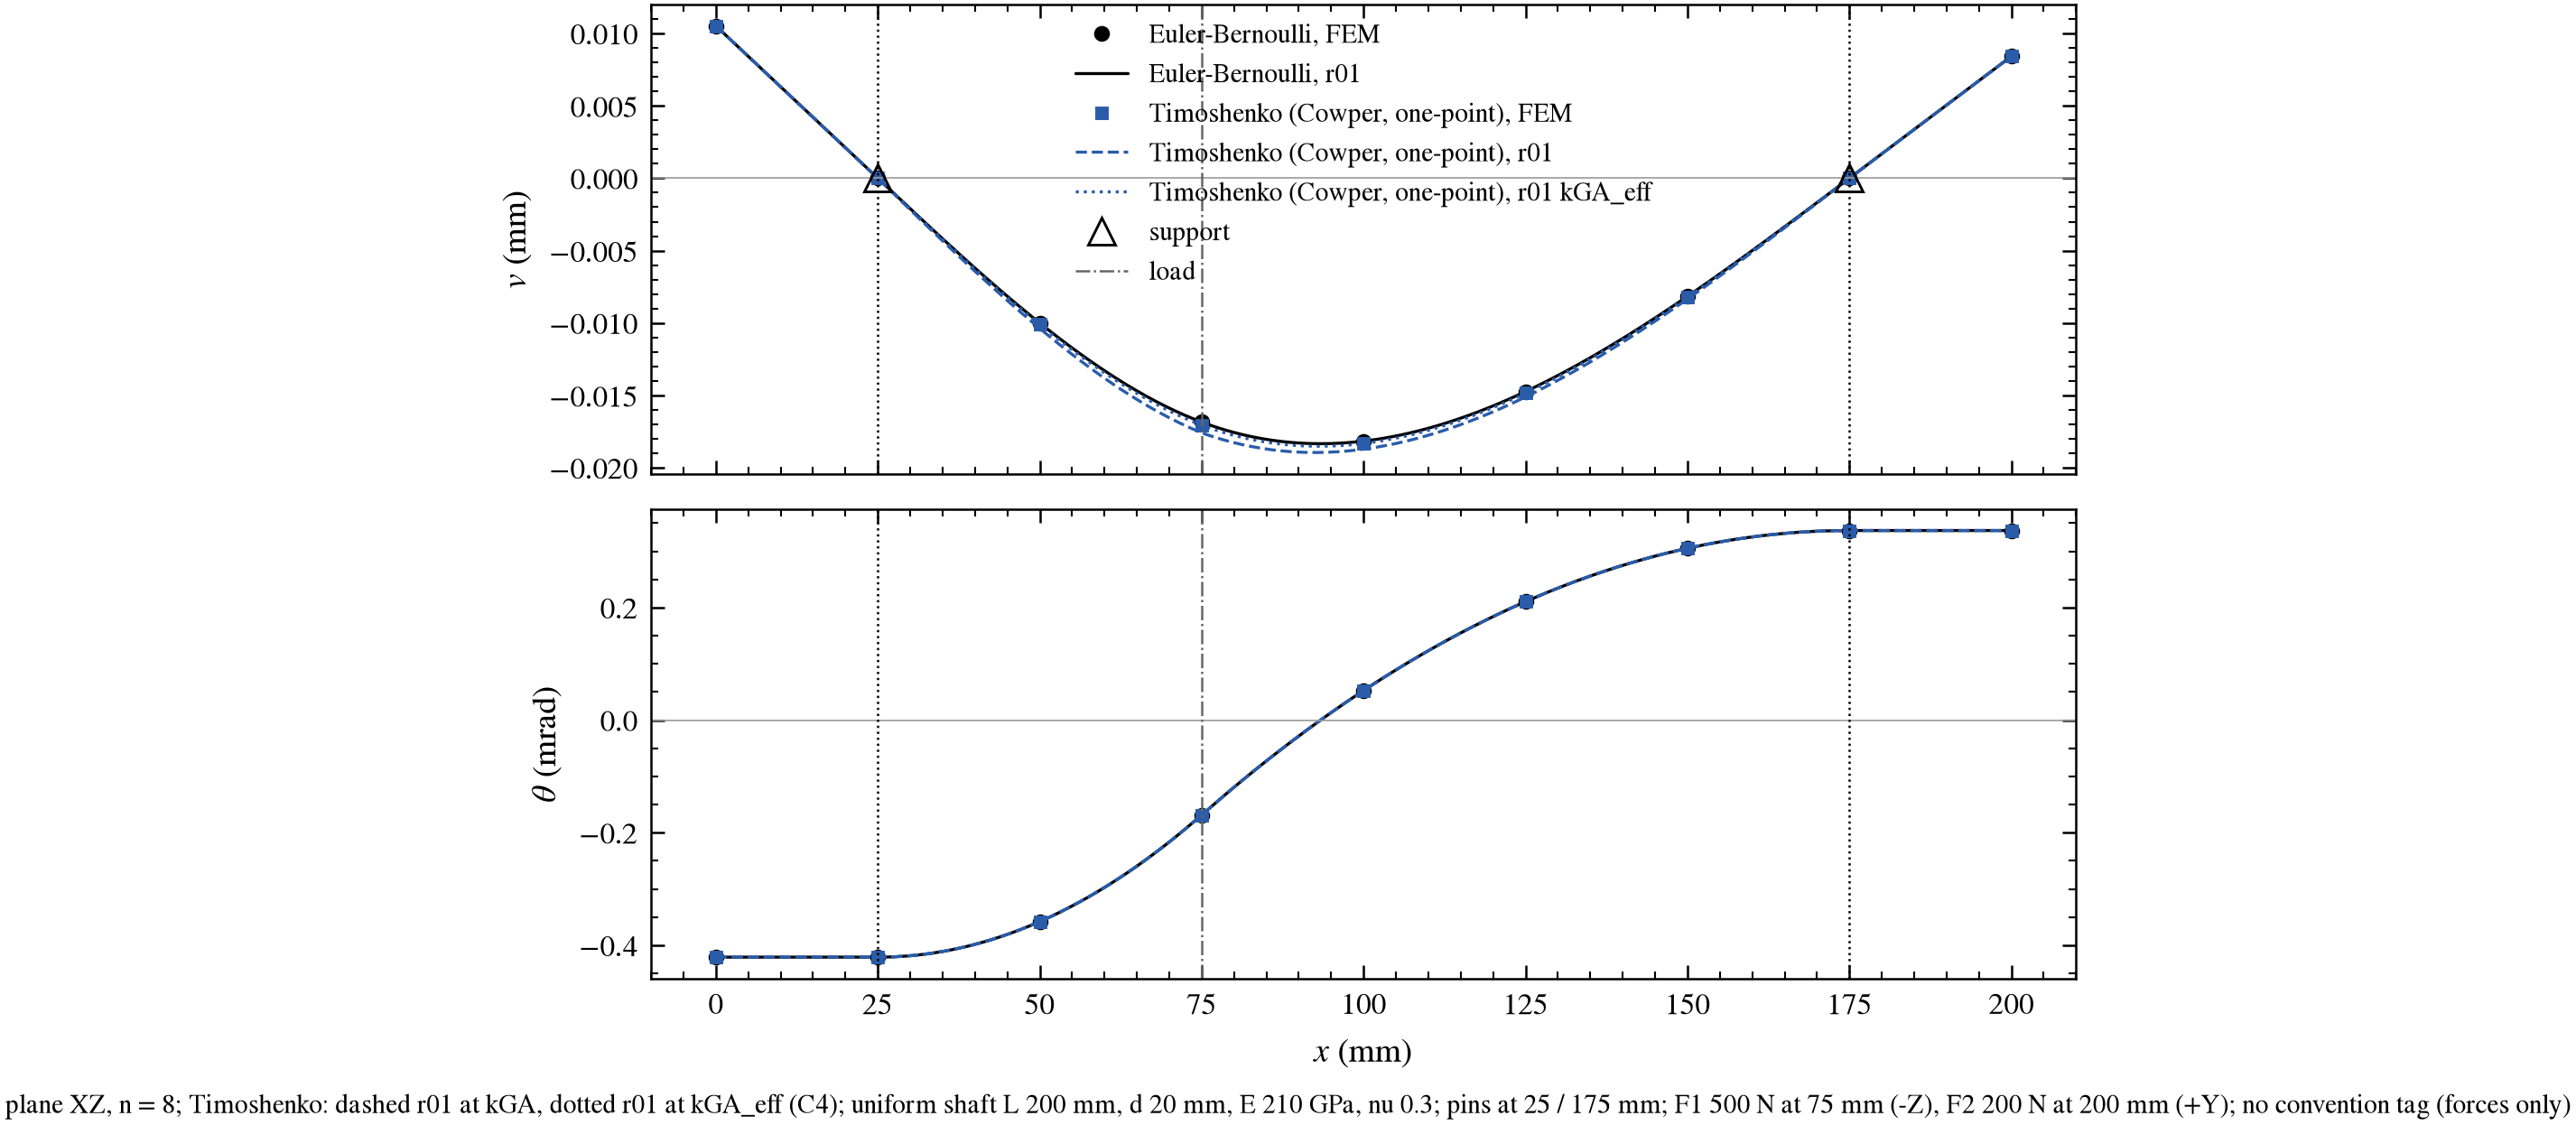

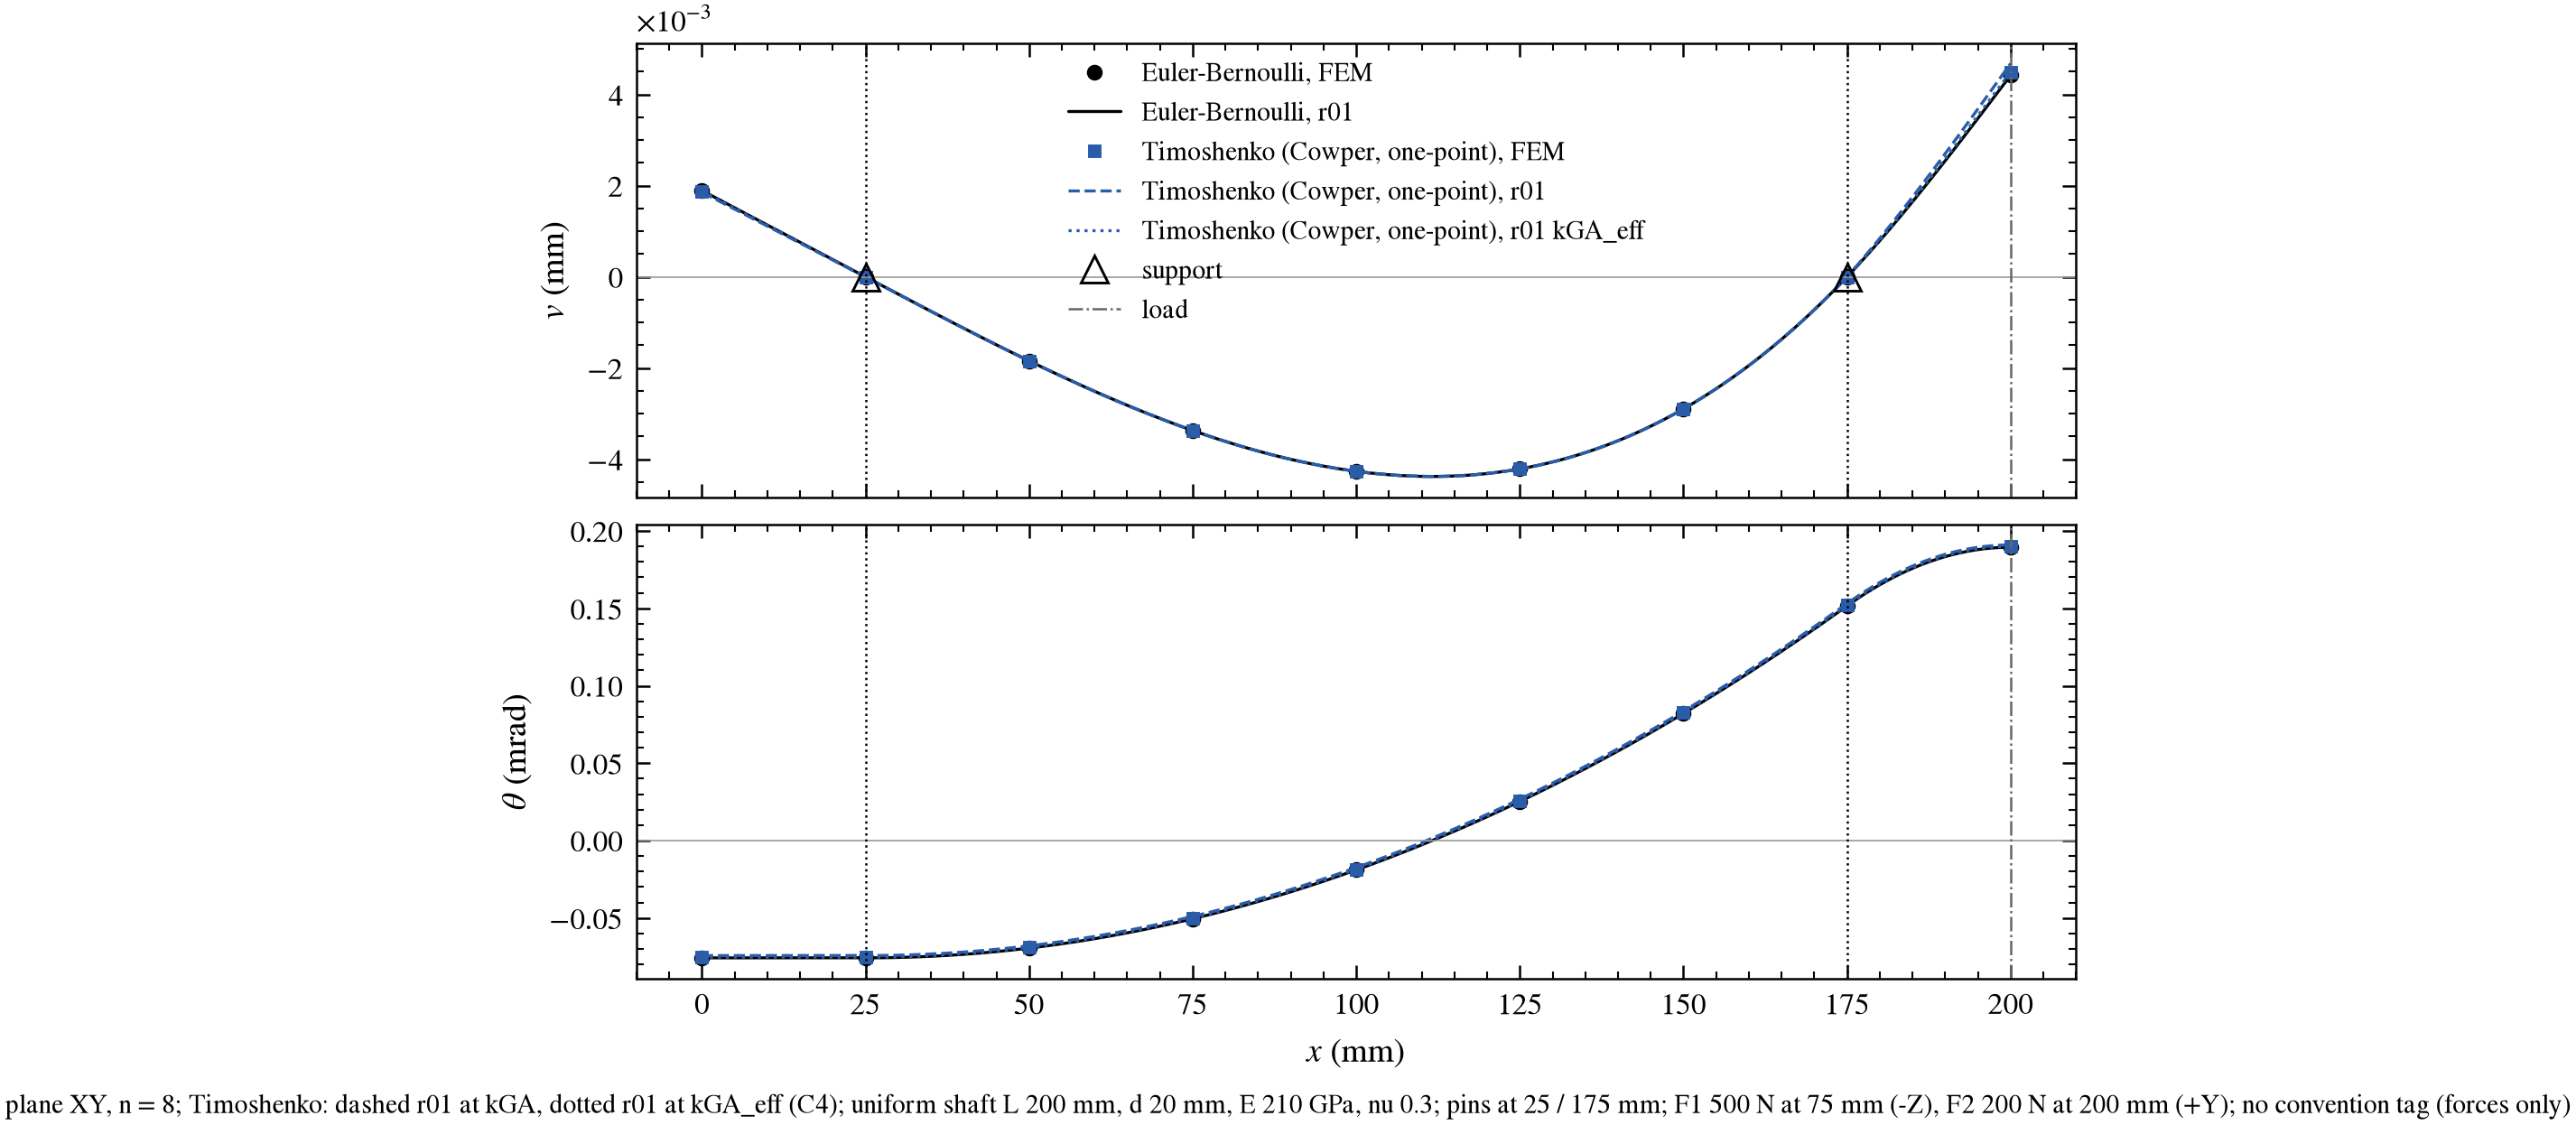

In [2]:
for f in out["figures"][:2]:
    display(Image(filename=str(f)))

## 2. Judged records (C1-C6) and the error against the number of elements

                            theory    n  plane  id              quantity    rel err    tol  verdict
----------------------------------  ---  -----  --  --------------------  ---------  -----  -------
                   euler_bernoulli    8     XZ  C1                     v   2.20e-15  1e-09     PASS
                   euler_bernoulli    8     XZ  C2                 theta   1.53e-15  1e-09     PASS
                   euler_bernoulli    8     XZ  C3                     R   1.19e-14  1e-09     PASS
                   euler_bernoulli    8     XY  C1                     v   3.68e-15  1e-09     PASS
                   euler_bernoulli    8     XY  C2                 theta   3.86e-15  1e-09     PASS
                   euler_bernoulli    8     XY  C3                     R   9.26e-15  1e-09     PASS
                   euler_bernoulli  128     XZ  C1                     v   1.22e-11  1e-09     PASS
                   euler_bernoulli  128     XZ  C2                 theta   1.02e-11  1e-09     PASS


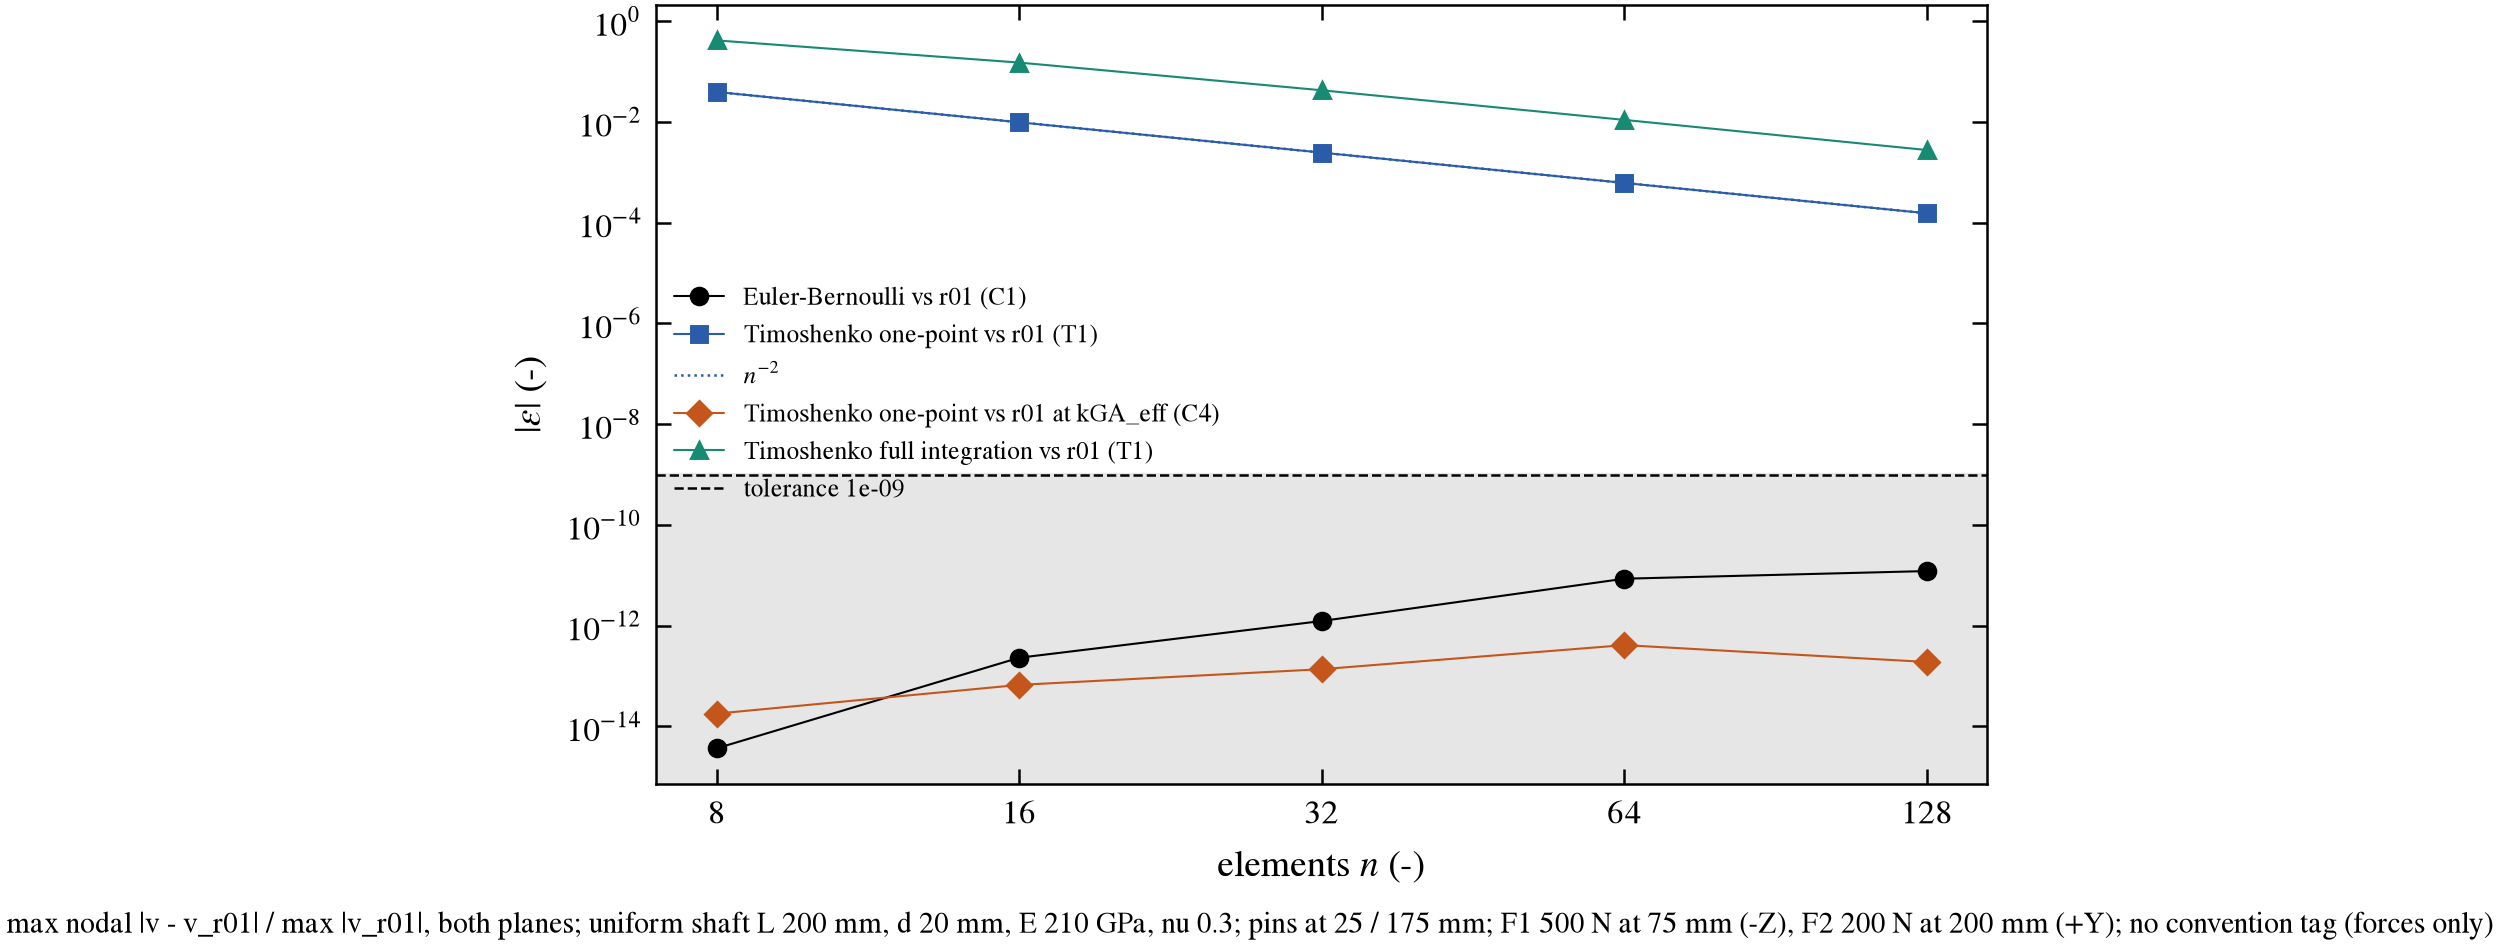

In [3]:
print(format_table((("theory", "theory", "s"), ("n_elements", "n", "d"), ("plane", "plane", "s"), ("id", "id", "s"),
                    ("quantity", "quantity", "s"), ("rel_err", "rel err", ".2e"), ("tol", "tol", ".0e"),
                    ("verdict", "verdict", "s")),
                   [r for r in out["check"] if r["verdict"] != "RECORD" and (r["n_elements"] in (8, 128))]))
display(Image(filename=str(out["figures"][2])))

## 3. Mesh series of the load-point deflection (Richardson, `numerical_solvers`)
Euler-Bernoulli is flat (nothing to extrapolate); one-point Timoshenko has p = 2 and extrapolates to r01;
full integration converges slowly from far (shear locking).

In [4]:
print(format_table((("theory", "theory", "s"), ("level", "n", ".0f"), ("value", "v [mm]", ".12f"),
                    ("status", "status", "s"), ("p", "p", ".6f"), ("f_extrapolated", "extrapolated [mm]", ".12f"),
                    ("gci_fine_medium", "GCI fm", ".2e"), ("r01_v_probe_mm", "r01 [mm]", ".12f")), out["richardson"]))

                            theory    n           v [mm]     status         p  extrapolated [mm]    GCI fm         r01 [mm]
----------------------------------  ---  ---------------  ---------  --------  -----------------  --------  ---------------
                   euler_bernoulli    8  -0.016841792920                    -                  -         -  -0.016841792920
                   euler_bernoulli   16  -0.016841792920                    -                  -         -  -0.016841792920
                   euler_bernoulli   32  -0.016841792920       flat         -    -0.016841792920  0.00e+00  -0.016841792920
                   euler_bernoulli   64  -0.016841792920       flat         -    -0.016841792920  0.00e+00  -0.016841792920
                   euler_bernoulli  128  -0.016841792920       flat         -    -0.016841792920  0.00e+00  -0.016841792920
    timoshenko/cowper/single_point    8  -0.017056525780                    -                  -         -  -0.017582831808
    timo

## 4. Shear effect: Timoshenko / Euler-Bernoulli at F1 against L/d (slender limit 1)

L/d       r01  FEM n=128    rel err
---  --------  ---------  ---------
  2  2.100000   2.099878  -5.81e-05
  3  1.488889   1.488767  -8.20e-05
  5  1.176000   1.175878  -1.04e-04
 10  1.044000   1.043878  -1.17e-04
 20  1.011000   1.010878  -1.21e-04
 50  1.001760   1.001638  -1.22e-04
100  1.000440   1.000318  -1.22e-04


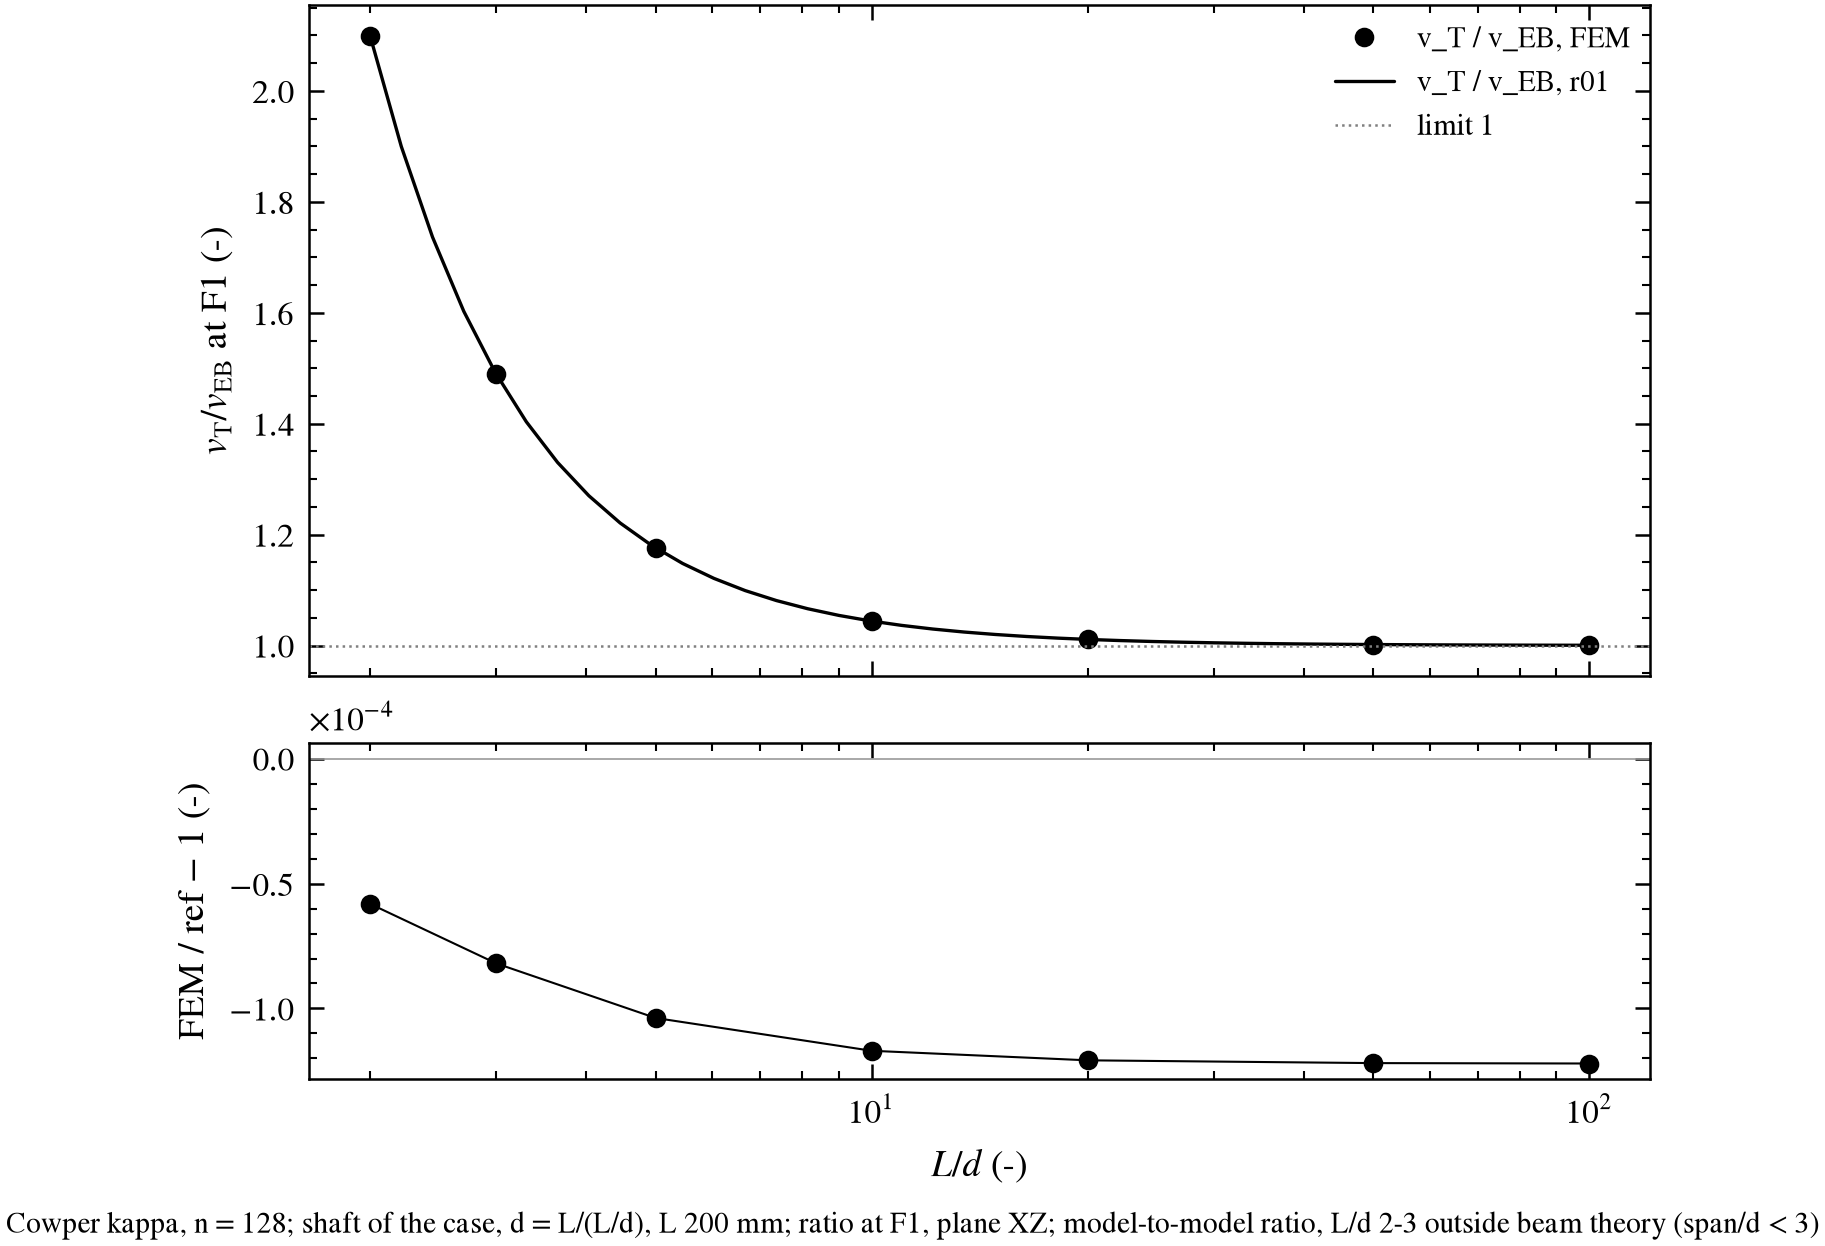

In [5]:
print(format_table((("L_over_d", "L/d", "g"), ("ratio_r01", "r01", ".6f"), ("ratio_fem", "FEM n=128", ".6f"),
                    ("rel_err_ratio", "rel err", ".2e")), out["shear"]))
display(Image(filename=str(out["figures"][3])))

## 5. Onate (2013): Table 2.1 (L1), Table 1.1 (L2), Table 2.3 (L3; L4 thick RECORD, nu and k_z not printed)

id      table                                       quantity     AxisForge   printed      tol  verdict
--  ---------  ---------------------------------------------  ------------  --------  -------  -------
L1  Table 2.1                                            r_w      0.750003      0.75  5.0e-04     PASS
L1  Table 2.1                                            r_w      0.937503     0.938  5.0e-04     PASS
L1  Table 2.1                                            r_w      0.984378     0.984  5.0e-04     PASS
L1  Table 2.1                                            r_w      0.996097     0.996  5.0e-04     PASS
L1  Table 2.1                                            r_w      0.999026     0.999  5.0e-04     PASS
L2  Table 1.1  central deflection error (C1 on Onate system)  -5.55112e-13         0  5.0e-03     PASS
L2  Table 1.1  central deflection error (C1 on Onate system)   -2.0528e-11         0  5.0e-03     PASS
L2  Table 1.1  central deflection error (C1 on Onate system)  -1.61915e-1

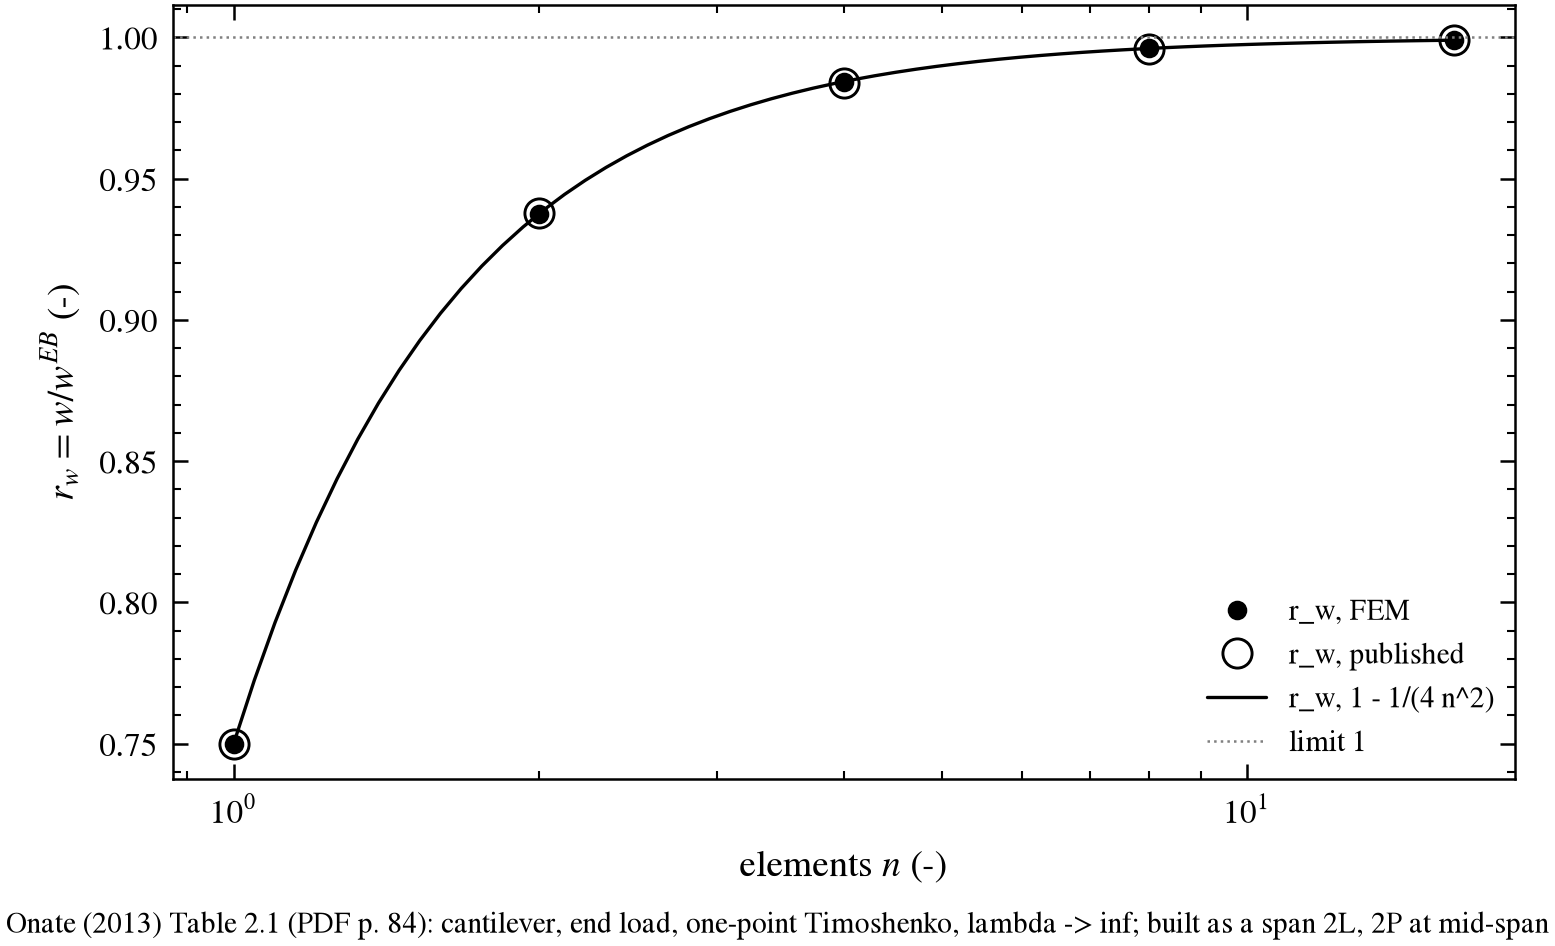

In [6]:
print(format_table((("id", "id", "s"), ("table", "table", "s"), ("quantity", "quantity", "s"),
                    ("measured", "AxisForge", ".6g"), ("reference", "printed", ".6g"), ("tol_abs", "tol", ".1e"),
                    ("verdict", "verdict", "s")), out["literature"]))
display(Image(filename=str(out["figures"][4])))

## 6. Verdict

In [7]:
rows = out["check"] + out["literature"]
judged = [r for r in rows if r["verdict"] != "RECORD"]
print(f"judged {len(judged)}, PASS {sum(r['verdict'] == 'PASS' for r in judged)}, "
      f"MISS {sum(r['verdict'] == 'MISS' for r in judged)}")

judged 120, PASS 120, MISS 0
